# Capacity of a Discrete Memoryless Channel (DMC)

This code is provided as supplementary material of the lecture Channel Coding 2 - Advanced Methods.

This code illustrates
* Calculating the channel capacity using convex optimization
* Calculating the capacity of weakly symmetric channels 

In [1]:
import cvxpy as cp
import numpy as np
import matplotlib.pyplot as plt

Helper function to check if a channel is weakly symmetric and hence also symmetric)

In [3]:
# check if channel is weakly symmetric
def is_weakly_symmetric(P):
    V = P.shape[1]
    W = P.shape[0]

    # check if matrix P is weakly symmetric
    col1 = np.sort(P[:,0])
    permutation_test = [np.array_equal(np.sort(P[:,k]), col1) for k in range(1,V)]

    retval = all(permutation_test)
    
    if retval == True:
        row_sums = np.sum(P,axis=1)
        if not all(row_sums == row_sums[0]):
            retval = False;
    
    return retval

Compute the capacity of a channel with input alphabet of size $V$ and output alphabet of size $W$, specified by a channel transmition matrix $\boldsymbol{P}$ of dimension $W\times V$. If the channel is weakly symmetric, use the direct equation
\begin{equation*}
C = \log_2(W) + \sum_{i=1}^W P_{i,1}\log_2P_{i,1}.
\end{equation*}
The capacity-achieving input distribution is
\begin{equation*}
\boldsymbol{p}_x = \begin{pmatrix} \frac{1}{V} & \cdots & \frac{1}{V}\end{pmatrix}^T
\end{equation*}
in that case.

If the channel is not weakly symmetric, use numerical optimization (here convex optimization, as we know that the mutual information is concave in the channel input distribution) to find the capacity and a capacity-achieving input distribution by solving the convex program
\begin{align*}
\text{maximize}\ \  & (\boldsymbol{1}_{1\times W}\cdot\tilde{\boldsymbol{P}})\boldsymbol{p}_x +\frac{1}{\ln(2)}\boldsymbol{1}_{1\times W}\cdot f_{\textrm{entr.}}(\boldsymbol{P}\boldsymbol{p}_x)\\
\text{subject to}\ &\sum_i p_{x,i} = 1\  \text{and}\  p_{x,i} \geq 0.
\end{align*}

How do we obtain this optimization problem? We start by calculating the _output probability vector_
\begin{equation*}
\boldsymbol{p}_y = \left(P(Y=y_1),\ldots,P(Y=y_W)\right)^T = \boldsymbol{P}\cdot\boldsymbol{p}_x
\end{equation*}
as $P(Y=y_j) = P(y_j) = \sum_i P(x_i,y_j) = \sum_i P(y_j|x_i)P(x_i)$.

Remember that $I(X;Y) = H(Y) - H(Y|X)$. Hence, with $\boldsymbol{1}_{1\times W}=(1, 1, \ldots, 1)$, we obtain
\begin{align*}
H(Y) & =-\sum_j P(y_j)\log_2P(y_j) \\
&= -(\boldsymbol{P}\boldsymbol{p}_x)^T\cdot \log_2(\boldsymbol{P}\boldsymbol{p}_x)\qquad (\text{where $\log_2(\cdot)$ is applied element-wise}) \\
&= \frac{1}{\ln(2)}\boldsymbol{1}_{1\times W}\cdot f_{\textrm{entr.}}(\boldsymbol{P}\boldsymbol{p}_x).
\end{align*}
Therein, the function $f_{\textrm{entr.}}$ is the so-called entropy function, which is defined as
\begin{alignat*}{2}
f_{\text{entr.}}\ :\ & \mathbb{R}^{W} &&\to \mathbb{R}^{W} \\
& \boldsymbol{p} &&\mapsto f_{\textrm{entr.}}(\boldsymbol{p}) = \begin{pmatrix}
f_{\textrm{entr.}}(p_1) \\ \vdots \\ f_{\textrm{entr.}}(p_W)
\end{pmatrix}
\end{alignat*}
where $f_{\textrm{entr.}}(p_i) = -p_i\ln p_i$. We use this formulation as the function $f_{\textrm{entr.}}$ is built into many software packages, for instance in cvxpy, which we use in this example.

Furthermore, we need to calculate $H(Y|X)$, and have
\begin{align*}
H(Y|X) &= -\sum_i\sum_jP(x_i,y_j)\log_2P(y_j|x_i)\\
&= -\sum_iP(x_i)\sum_jP(y_j|x_i)\log_2P(y_j|x_i) = -(\boldsymbol{1}_{1\times W}\cdot\tilde{\boldsymbol{P}})\boldsymbol{p}_x
\end{align*}
with $\tilde{\boldsymbol{P}} = \boldsymbol{P}\odot \log_2(\boldsymbol{P})$ ($\odot \mathrel{\widehat{=}}$ denoting element-wise multiplication) and $\boldsymbol{1}_{1\times W}=(1, 1, \ldots, 1)$.

As a reminder, we have
\begin{equation*}
\begin{pmatrix}a & b \\ c & d \end{pmatrix}\odot\begin{pmatrix}
e & f \\ g & h
\end{pmatrix} = \begin{pmatrix}
ae & bf \\
cg & dh
\end{pmatrix}.
\end{equation*}
We can thus compute the mutual information
\begin{equation*}
I(X;Y) = \frac{1}{\ln(2)}\boldsymbol{1}_{1\times W}\cdot f_{\textrm{entr.}}(\boldsymbol{P}\boldsymbol{p}_x) + (\boldsymbol{1}_{1\times W}\cdot\tilde{\boldsymbol{P}})\boldsymbol{p}_x.
\end{equation*}
As
\begin{equation*}
C_{\text{DMC}} = \max_{\boldsymbol{p}_x}I(X;Y) = \max_{\boldsymbol{p}_x}\left[(\boldsymbol{1}_{1\times W}\cdot\tilde{\boldsymbol{P}})\boldsymbol{p}_x +\frac{1}{\ln(2)}\boldsymbol{1}_{1\times W}\cdot f_{\textrm{entr.}}(\boldsymbol{P}\boldsymbol{p}_x)\right]
\end{equation*}
and $I(X;Y)$ is a concave function of $\boldsymbol{p}_x$ for a fixed channel (see Thomas M. Cover and Joy A. Thomas, *Elements of Information Theory*, 2nd ed., John Wiley & Sons, 2006, Theorem 2.7.4, p. 33), this is a convex optimization problem. A global maximum exists because the objective is continuous on the compact probability simplex, and it can be found by convex programming. The capacity-achieving input distribution need not be unique. We additionally need to make sure that the optimization variables $p_{x,i}$ represent probabilities, i.e., $0 \leq p_{x,i} \leq 1$ and $\sum_ip_{x,i} = 1$. Due to the non-negativity of $p_{x,i}$. the upper limit is implicit from the sum constraint and does not need to be specified.

In [4]:
def channel_capacity(P):
    # input and output dimensions
    V = P.shape[1]
    W = P.shape[0]

    if is_weakly_symmetric(P):
        col = P[:,0]
        C = np.log2(W) + np.sum(col * np.log2(col))
        px = np.ones(V)/V
        
        return C,px
    else:
        # compute Ptilde, multiplication is element-wise here (not matrix multiplication!)
        Ptilde = np.zeros_like(P)
                
        Ptilde[P > 0] = P[P > 0] * np.log2(P[P > 0])
        Ptilde[np.isnan(Ptilde)] = 0   # case 0*log2(0) = 0 (and not inf/nan)
                
        # optimize Px
        px = cp.Variable(shape=V)
    
        objective = cp.Maximize(np.sum(Ptilde,axis=0)@px + cp.sum(cp.entr(P@px))/np.log(2.0))
        constraints = [cp.sum(px) == 1.0, px >= 0]
        
        problem = cp.Problem(objective, constraints)
        problem.solve()
        
        return problem.value, px.value        


Compute the capacity for the weakly symmetric channel used in the lecture

In [5]:
# channel transition matrix of a symmetric channel
P = np.array([[1/3, 1/3], [1/2, 1/6], [1/6, 1/2]])
print(channel_capacity(P))

(np.float64(0.1258145836939113), array([0.5, 0.5]))


Compute the capacity for a non-symmetric channel. Observe that the input distribution is not uniform

In [6]:
# channel transition matrix of an arbitrary channel
P = np.array([[1/2, 1/8], [1/3, 5/8], [1/6, 1/4]])
print(channel_capacity(P))

(np.float64(0.1259246564433405), array([0.46964687, 0.53035312]))


Compute the capacity for a Z-channel with error probability $q=0.1$

In [7]:
# Z-channel
q = 0.1
P = np.array([[1, q], [0, 1-q]])
print(channel_capacity(P))

(np.float64(0.7628482538670132), array([0.54369442, 0.45630558]))


Compute capacitiies of the Z-channel with a varying range of input parameters

In [8]:
qs = np.linspace(0.00001,0.99999,100)
Cs = np.zeros_like(qs)
pxs = np.empty((0,2))
for k in range(len(qs)):
    P = np.array([[1, qs[k]], [0, 1-qs[k]]])
    C,px = channel_capacity(P)
    Cs[k] = C
    pxs = np.vstack((pxs,px))

Text(0, 0.5, 'C (bit/channel use)')

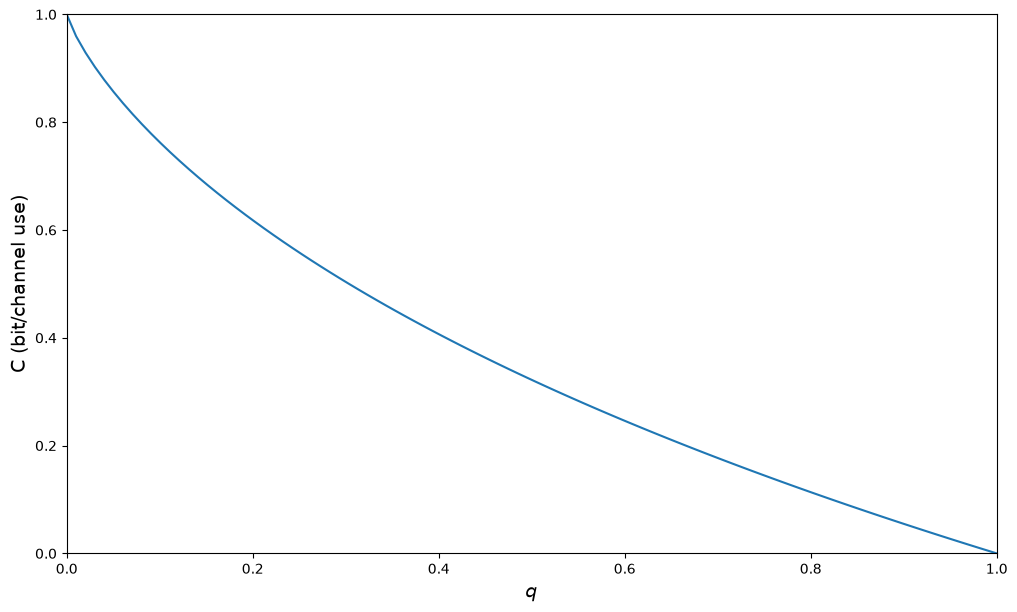

In [9]:
plt.figure(figsize=(12,7))
plt.plot(qs, Cs)
plt.xlim((0,1))
plt.ylim((0,1))
plt.xlabel('$q$',fontsize=14)
plt.ylabel('C (bit/channel use)',fontsize=14)

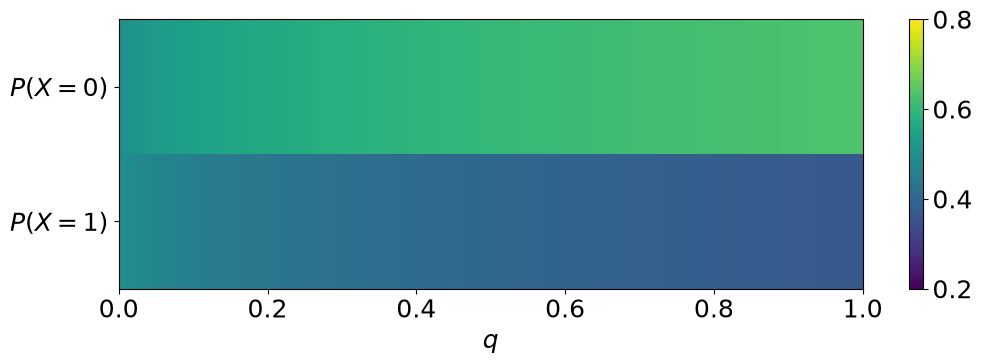

In [10]:
plt.figure(figsize=(12,3.5))
font = {'size'   : 18}
plt.rc('font', **font)
#plt.rc('text', usetex=True)
plt.imshow(pxs.T, extent=[0, qs[-1], -1, 1], aspect='auto', vmin=0.2, vmax=0.8)
plt.xlim(0,1)
plt.xlabel('$q$')
plt.yticks([-0.5, 0.5], ('$P(X=1)$', '$P(X=0)$'))
plt.colorbar();
#plt.savefig('Zchannel_input_distribution.pdf',bbox_inches='tight')